Mounted at /content/drive
Archivo encontrado en: /content/drive/MyDrive/Tesis_caso/estaciones_viajes_alcaldias.csv
Filas: 141,147 | Columnas: ['anio_archivo', 'mes_archivo', 'ciclo_estacion_retiro', 'genero', 'n_viajes', 'edad_promedio', 'suma_edad', 'n_edad_validas', 'nombre_estacion', 'alcaldia']
Meses con datos disponibles por año (para detectar años incompletos):
anio_archivo
2020    12
2021    12
2022    11
2023    12
2024    12
2025    12
2026     8
Name: meses_con_datos, dtype: int64

Total de viajes por año y alcaldía:


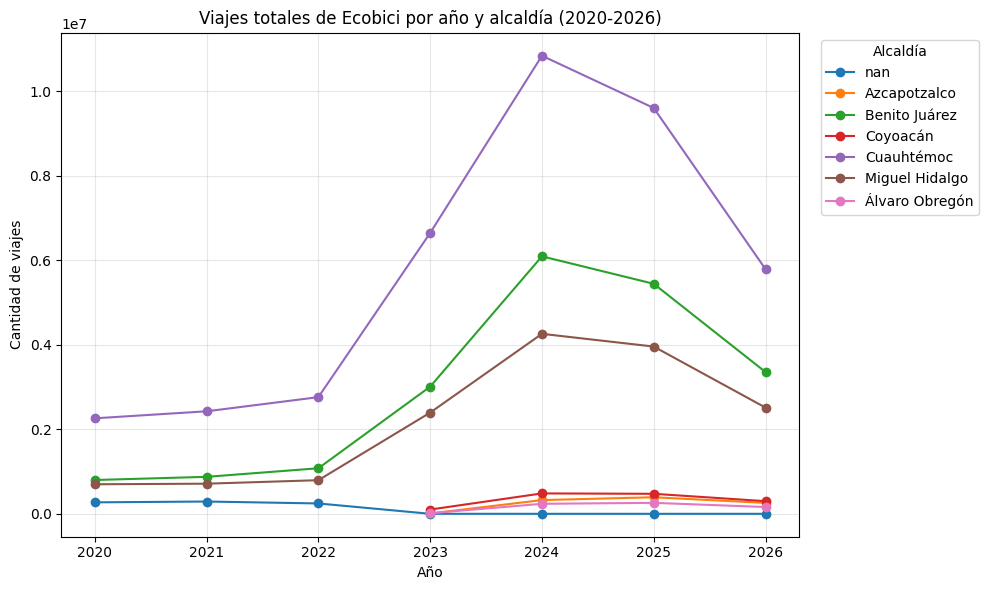

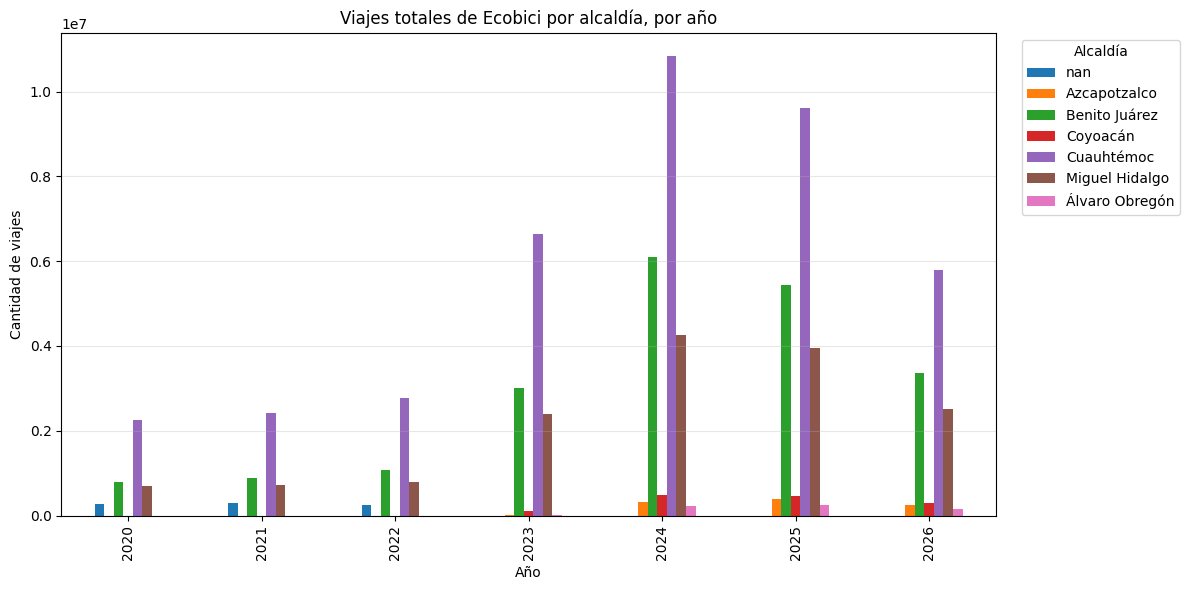

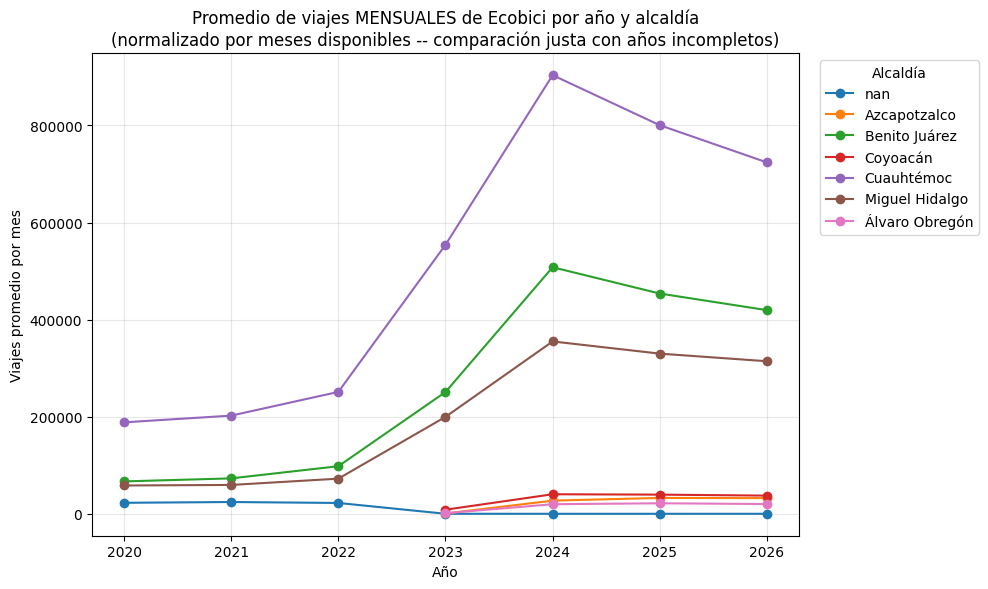

Tabla guardada en: /content/drive/MyDrive/ecobici_viajes_por_anio_alcaldia.csv


In [ ]:
# =============================================================================
# ECOBICI - EVOLUCIÓN DEL USO POR AÑO Y ALCALDÍA (2020-2026)
# =============================================================================
# Objetivo: a partir de estaciones_viajes_alcaldias.csv, graficar cómo ha
# cambiado el número de viajes por alcaldía a lo largo de los años.
# Eje X = año, una línea/serie por cada una de las 6 alcaldías.
# =============================================================================

# ETAPA 0: Montar Drive e importar librerías
# -----------------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

import glob
import pandas as pd
import matplotlib.pyplot as plt


# ETAPA 1: Cargar el archivo
# -----------------------------------------------------------------------
# Lo buscamos por nombre en todo el Drive, por si no está en la raíz.

coincidencias = glob.glob("/content/drive/MyDrive/**/estaciones_viajes_alcaldias.csv", recursive=True)
if not coincidencias:
    raise FileNotFoundError("No encontré 'estaciones_viajes_alcaldias.csv' en tu Drive.")

RUTA_DATOS = coincidencias[0]
print(f"Archivo encontrado en: {RUTA_DATOS}")

df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]:,} | Columnas: {list(df.columns)}")
df.head()



# ETAPA 2: Agregar -- total de viajes por año y alcaldía
# -----------------------------------------------------------------------
# El archivo viene desglosado por año, mes, estación y género. Aquí lo
# colapsamos a un solo número por año + alcaldía (sumando todos los meses,
# estaciones y géneros).

viajes_por_anio_alcaldia = (
    df
    .groupby(["anio_archivo", "alcaldia"], dropna=False)["n_viajes"]
    .sum()
    .reset_index()
    .rename(columns={"anio_archivo": "anio"})
)

# Además, contamos cuántos MESES distintos tiene cada año en los datos --
# esto nos sirve para detectar si 2026 (u otro año) está incompleto.
meses_por_anio = (
    df[["anio_archivo", "mes_archivo"]]
    .drop_duplicates()
    .groupby("anio_archivo")
    .size()
    .rename("meses_con_datos")
)

print("Meses con datos disponibles por año (para detectar años incompletos):")
print(meses_por_anio)

# Tabla "ancha": una fila por año, una columna por alcaldía -- ideal para graficar.
tabla_viajes = viajes_por_anio_alcaldia.pivot(index="anio", columns="alcaldia", values="n_viajes")
tabla_viajes = tabla_viajes.sort_index()

print("\nTotal de viajes por año y alcaldía:")
tabla_viajes


# ETAPA 3: Gráfica de líneas -- evolución del total de viajes por alcaldía
# -----------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

for alcaldia in tabla_viajes.columns:
    ax.plot(tabla_viajes.index, tabla_viajes[alcaldia], marker="o", label=alcaldia)

ax.set_title("Viajes totales de Ecobici por año y alcaldía (2020-2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Cantidad de viajes")
ax.legend(title="Alcaldía", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# %% [Celda 5] -----------------------------------------------------------
# ETAPA 4: Gráfica de barras agrupadas -- mismo dato, otra vista
# -----------------------------------------------------------------------
# Útil para comparar alcaldías DENTRO de un mismo año, en vez de ver
# tendencias a lo largo del tiempo.

tabla_viajes.plot(
    kind="bar",
    figsize=(12, 6),
    title="Viajes totales de Ecobici por alcaldía, por año",
)
plt.xlabel("Año")
plt.ylabel("Cantidad de viajes")
plt.legend(title="Alcaldía", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


# %% [Celda 6] -----------------------------------------------------------
# ETAPA 5: Versión normalizada -- promedio de viajes POR MES
# -----------------------------------------------------------------------
# IMPORTANTE: si algún año (típicamente el más reciente, 2026) no tiene
# los 12 meses completos todavía, su total se ve artificialmente bajo
# comparado con años completos. Esta gráfica divide el total entre los
# meses realmente disponibles en cada año, para una comparación más justa.

tabla_viajes_promedio_mensual = tabla_viajes.div(meses_por_anio, axis=0)

fig, ax = plt.subplots(figsize=(10, 6))
for alcaldia in tabla_viajes_promedio_mensual.columns:
    ax.plot(tabla_viajes_promedio_mensual.index, tabla_viajes_promedio_mensual[alcaldia],
            marker="o", label=alcaldia)

ax.set_title("Promedio de viajes MENSUALES de Ecobici por año y alcaldía\n"
             "(normalizado por meses disponibles -- comparación justa con años incompletos)")
ax.set_xlabel("Año")
ax.set_ylabel("Viajes promedio por mes")
ax.legend(title="Alcaldía", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# %% [Celda 7] -----------------------------------------------------------
# ETAPA 6 (opcional): Guardar la tabla resumen usada en las gráficas
# -----------------------------------------------------------------------

RUTA_SALIDA = "/content/drive/MyDrive/ecobici_viajes_por_anio_alcaldia.csv"
tabla_viajes.to_csv(RUTA_SALIDA)
print(f"Tabla guardada en: {RUTA_SALIDA}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Alcaldías usadas en el análisis de Ecobici (7): ['Unnamed: 1', 'Azcapotzalco', 'Benito Juárez', 'Coyoacán', 'Cuauhtémoc', 'Miguel Hidalgo', 'Álvaro Obregón']
Archivo de seguridad encontrado en: /content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv
Filas: 400 | Columnas: ['anio', 'mes', 'trimestre', 'region', 'alcaldia', 'poblacion_18mas', 'seguro_abs', 'seguro_pct', 'inseguro_abs', 'inseguro_pct']
Alcaldías de Ecobici encontradas en el archivo de seguridad: ['Azcapotzalco', 'Benito Juárez', 'Coyoacán', 'Cuauhtémoc', 'Miguel Hidalgo', 'Álvaro Obregón']
[AVISO] No se encontraron en el archivo de seguridad: ['Unnamed: 1']

Filas después del filtro: 150
% de percepción de seguridad por año y alcaldía:


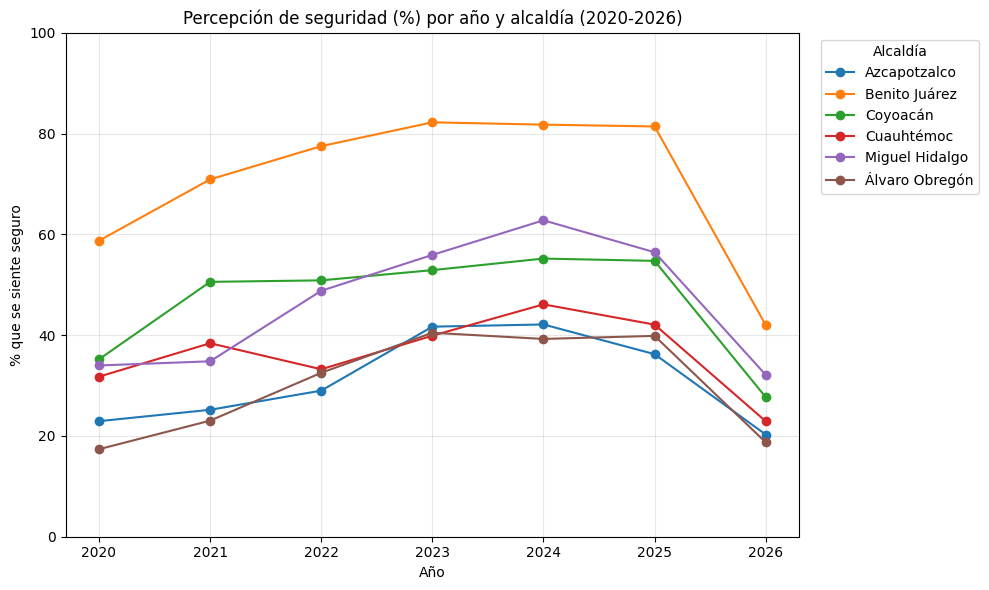

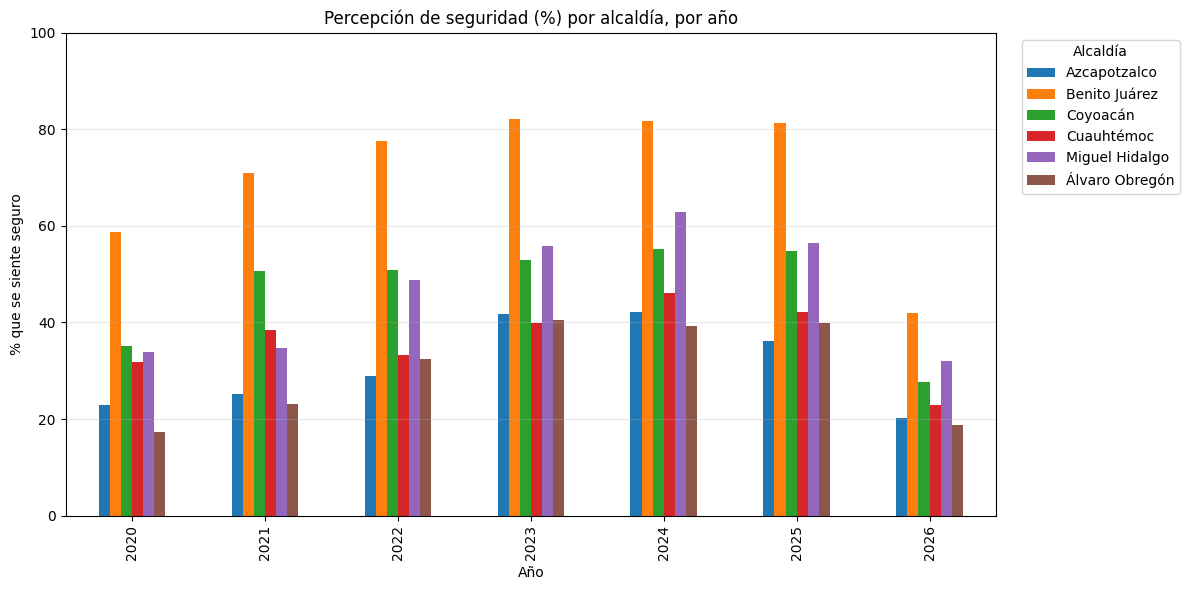

Tabla guardada en: /content/drive/MyDrive/ecobici_seguridad_por_anio_alcaldia.csv


In [ ]:
# =============================================================================
# PERCEPCIÓN DE SEGURIDAD (ENSU) - EVOLUCIÓN POR AÑO Y ALCALDÍA (2020-2026)
# =============================================================================
# Objetivo: graficar el % de percepción de seguridad por alcaldía a lo largo
# de los años, usando SOLO las 6 alcaldías que ya se usaron en el análisis
# de Ecobici (para que ambos análisis sean comparables entre sí).
# =============================================================================



# ETAPA 0: Montar Drive e importar librerías
# -----------------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

import os
import re
import glob
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt


def normalizar_texto(texto: str) -> str:
    """Minúsculas, sin acentos, espacios -> guion_bajo (para cruzar nombres
    de alcaldía aunque vengan escritos ligeramente distinto entre archivos)."""
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    texto = re.sub(r"[^a-z0-9]+", "_", texto).strip("_")
    return texto

# ETAPA 1: Cargar las 6 alcaldías ya usadas en el análisis de Ecobici
# -----------------------------------------------------------------------

RUTA_ECOBICI_ALCALDIAS = "/content/drive/MyDrive/ecobici_viajes_por_anio_alcaldia.csv"
tabla_ecobici = pd.read_csv(RUTA_ECOBICI_ALCALDIAS, index_col="anio")

alcaldias_ecobici = list(tabla_ecobici.columns)
alcaldias_ecobici_norm = {normalizar_texto(a): a for a in alcaldias_ecobici}

print(f"Alcaldías usadas en el análisis de Ecobici ({len(alcaldias_ecobici)}): {alcaldias_ecobici}")


# ETAPA 2: Cargar el CSV de percepción de seguridad
# -----------------------------------------------------------------------
# AJUSTA el nombre del archivo si el buscador automático no lo encuentra.

patrones_posibles = ["*seguridad*.csv", "*ensu*.csv", "*percepcion*.csv"]
coincidencias = []
for patron in patrones_posibles:
    coincidencias += glob.glob(f"/content/drive/MyDrive/**/{patron}", recursive=True)

if not coincidencias:
    raise FileNotFoundError(
        "No encontré automáticamente el CSV de seguridad. "
        "Copia su ruta exacta desde Drive y ponla manualmente en RUTA_SEGURIDAD."
    )

RUTA_SEGURIDAD = coincidencias[0]
print(f"Archivo de seguridad encontrado en: {RUTA_SEGURIDAD}")

df_seguridad = pd.read_csv(RUTA_SEGURIDAD)
print(f"Filas: {df_seguridad.shape[0]:,} | Columnas: {list(df_seguridad.columns)}")
df_seguridad.head()

# ETAPA 3: Filtrar -- solo años 2020-2026 y solo las 6 alcaldías de Ecobici
# -----------------------------------------------------------------------

ANIO_MIN, ANIO_MAX = 2020, 2026

df_seguridad["alcaldia_norm"] = df_seguridad["alcaldia"].apply(normalizar_texto)

df_filtrado = df_seguridad[
    df_seguridad["anio"].between(ANIO_MIN, ANIO_MAX)
    & df_seguridad["alcaldia_norm"].isin(alcaldias_ecobici_norm.keys())
].copy()

# Usamos el nombre de alcaldía TAL COMO viene en el archivo de Ecobici,
# para que ambas tablas queden con exactamente el mismo texto.
df_filtrado["alcaldia"] = df_filtrado["alcaldia_norm"].map(alcaldias_ecobici_norm)

alcaldias_encontradas = sorted(df_filtrado["alcaldia"].unique())
alcaldias_no_encontradas = sorted(set(alcaldias_ecobici) - set(alcaldias_encontradas))

print(f"Alcaldías de Ecobici encontradas en el archivo de seguridad: {alcaldias_encontradas}")
if alcaldias_no_encontradas:
    print(f"[AVISO] No se encontraron en el archivo de seguridad: {alcaldias_no_encontradas}")

print(f"\nFilas después del filtro: {len(df_filtrado):,}")


# ETAPA 4: Agregar -- % de seguridad promedio POR AÑO Y ALCALDÍA
# -----------------------------------------------------------------------
# El archivo trae un dato por trimestre/periodo. Para obtener un solo valor
# por año, usamos un PROMEDIO PONDERADO por población encuestada (seguro_abs
# / poblacion_18mas), en vez de promediar directo los porcentajes -- así
# los trimestres con más población encuestada pesan más, y es coherente
# aunque falte algún trimestre en algún año.

resumen_seguridad = (
    df_filtrado
    .groupby(["anio", "alcaldia"], dropna=False)
    .agg(
        seguro_abs_total=("seguro_abs", "sum"),
        poblacion_total=("poblacion_18mas", "sum"),
        n_periodos=("trimestre", "nunique"),
    )
    .reset_index()
)
resumen_seguridad["seguro_pct"] = (
    resumen_seguridad["seguro_abs_total"] / resumen_seguridad["poblacion_total"] * 100
)
resumen_seguridad["inseguro_pct"] = 100 - resumen_seguridad["seguro_pct"]

tabla_seguro_pct = resumen_seguridad.pivot(index="anio", columns="alcaldia", values="seguro_pct").sort_index()

# Reordenamos las columnas igual que en la tabla de Ecobici, para que las
# gráficas de ambos análisis sean visualmente comparables (mismo orden/colores).
tabla_seguro_pct = tabla_seguro_pct[[a for a in alcaldias_ecobici if a in tabla_seguro_pct.columns]]

print("% de percepción de seguridad por año y alcaldía:")
tabla_seguro_pct


fig, ax = plt.subplots(figsize=(10, 6))

for alcaldia in tabla_seguro_pct.columns:
    ax.plot(tabla_seguro_pct.index, tabla_seguro_pct[alcaldia], marker="o", label=alcaldia)

ax.set_title("Percepción de seguridad (%) por año y alcaldía (2020-2026)")
ax.set_xlabel("Año")
ax.set_ylabel("% que se siente seguro")
ax.set_ylim(0, 100)
ax.legend(title="Alcaldía", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


tabla_seguro_pct.plot(
    kind="bar",
    figsize=(12, 6),
    title="Percepción de seguridad (%) por alcaldía, por año",
)
plt.xlabel("Año")
plt.ylabel("% que se siente seguro")
plt.ylim(0, 100)
plt.legend(title="Alcaldía", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


# %% [Celda 8] -----------------------------------------------------------
# ETAPA 7 (opcional): Guardar la tabla resumen usada en las gráficas
# -----------------------------------------------------------------------

RUTA_SALIDA = "/content/drive/MyDrive/ecobici_seguridad_por_anio_alcaldia.csv"
tabla_seguro_pct.to_csv(RUTA_SALIDA)
print(f"Tabla guardada en: {RUTA_SALIDA}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Años en común: [2020, 2021, 2022, 2023, 2024, 2025, 2026]
Alcaldías en común: ['Azcapotzalco', 'Benito Juárez', 'Coyoacán', 'Cuauhtémoc', 'Miguel Hidalgo', 'Álvaro Obregón']


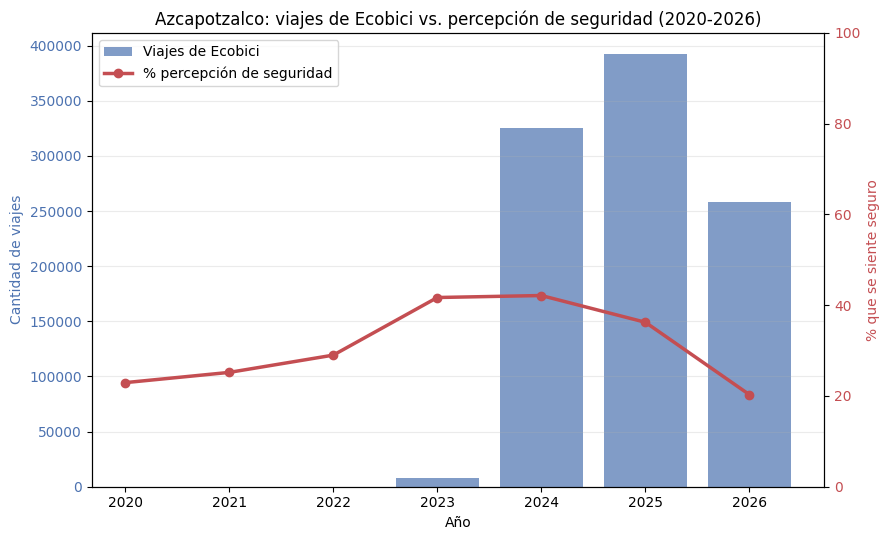

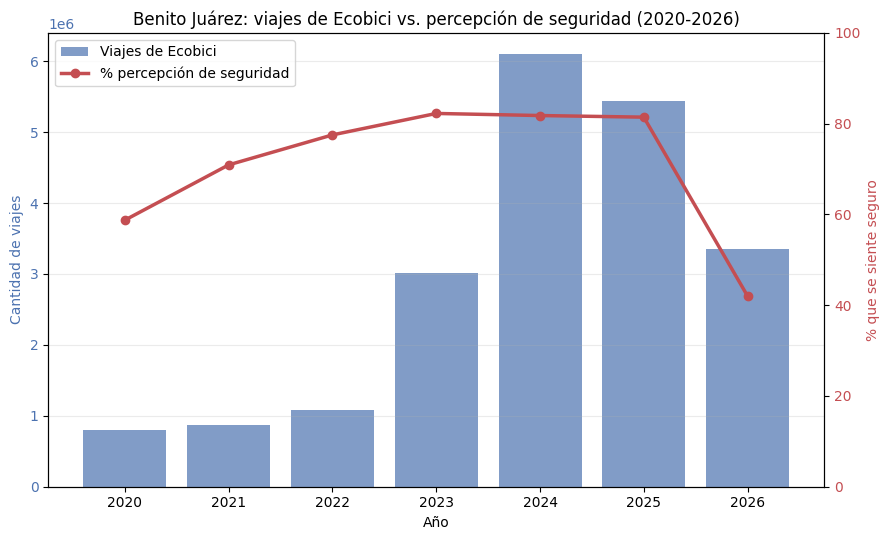

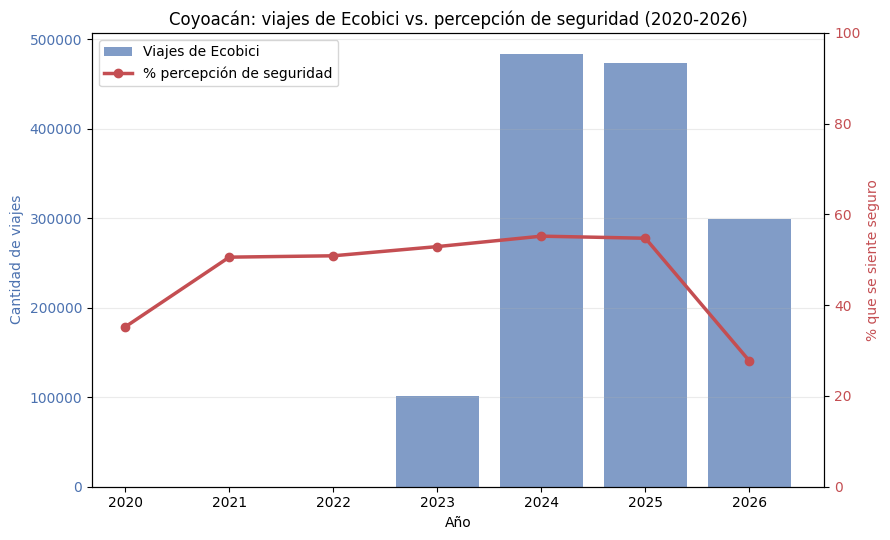

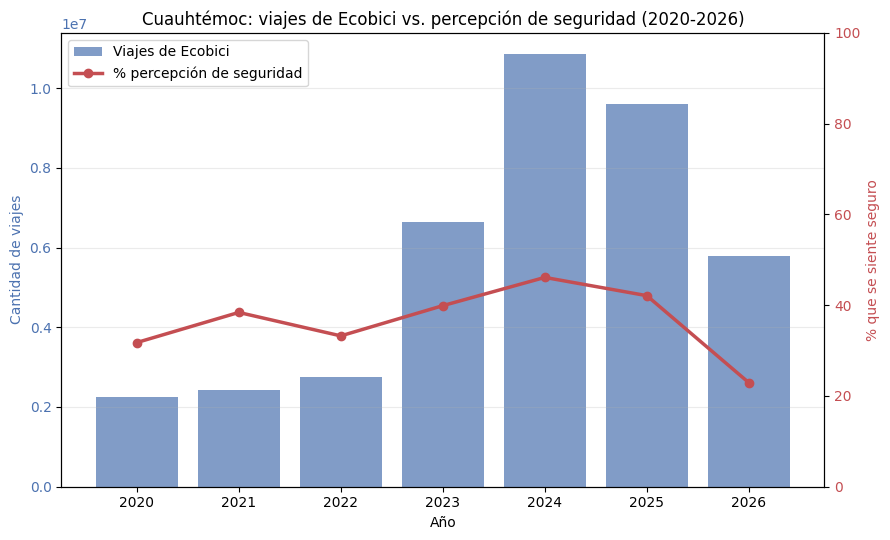

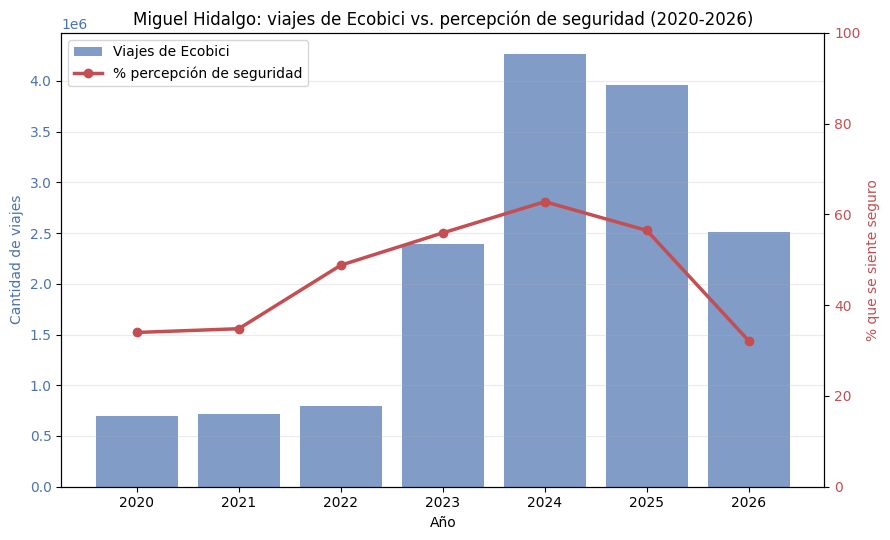

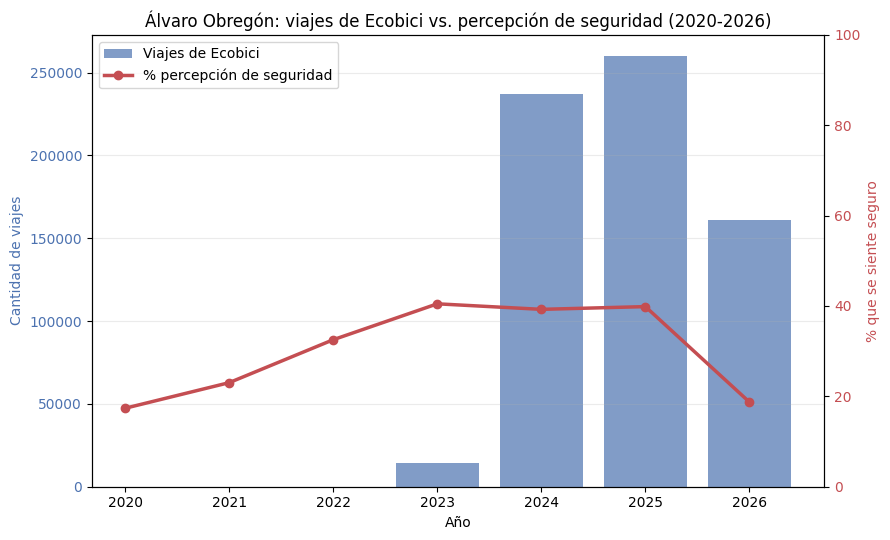

Correlación (Pearson) entre viajes de Ecobici y % de percepción de seguridad, por alcaldía:
Miguel Hidalgo    0.704244
Cuauhtémoc        0.573763
Benito Juárez     0.316841
Coyoacán          0.220189
Álvaro Obregón    0.004673
Azcapotzalco     -0.200316
Name: correlacion_viajes_vs_seguridad, dtype: float64


In [ ]:
# =============================================================================
# ECOBICI vs PERCEPCIÓN DE SEGURIDAD - UNA GRÁFICA COMBINADA POR ALCALDÍA
# =============================================================================
# Objetivo: para cada una de las 6 alcaldías, una sola gráfica que muestre
# a la vez:
#   - Cantidad de viajes de Ecobici por año (eje izquierdo, barras)
#   - % de percepción de seguridad por año (eje derecho, línea)
# Como son magnitudes de escalas muy distintas (cientos de miles de viajes
# vs. un porcentaje de 0-100), se usa un eje Y doble (twin axis) -- es la
# forma correcta de comparar dos series con unidades distintas en una
# misma gráfica sin que una aplaste visualmente a la otra.
# =============================================================================


# ETAPA 0: Montar Drive e importar librerías
# -----------------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt


# ETAPA 1: Cargar las dos tablas ya generadas (viajes y seguridad)
# -----------------------------------------------------------------------

RUTA_VIAJES = "/content/drive/MyDrive/ecobici_viajes_por_anio_alcaldia.csv"
RUTA_SEGURIDAD = "/content/drive/MyDrive/ecobici_seguridad_por_anio_alcaldia.csv"

tabla_viajes = pd.read_csv(RUTA_VIAJES, index_col="anio")
tabla_seguro_pct = pd.read_csv(RUTA_SEGURIDAD, index_col="anio")

# Nos quedamos solo con los años que existen en AMBAS tablas, y con las
# alcaldías que existen en ambas también, para que la comparación sea
# consistente (sin huecos por un lado y no por el otro).
anios_comunes = sorted(set(tabla_viajes.index) & set(tabla_seguro_pct.index))
alcaldias_comunes = [a for a in tabla_viajes.columns if a in tabla_seguro_pct.columns]

tabla_viajes = tabla_viajes.loc[anios_comunes, alcaldias_comunes]
tabla_seguro_pct = tabla_seguro_pct.loc[anios_comunes, alcaldias_comunes]

print(f"Años en común: {anios_comunes}")
print(f"Alcaldías en común: {alcaldias_comunes}")


# %% [Celda 3] -----------------------------------------------------------
# ETAPA 2: Una gráfica combinada (doble eje) por cada alcaldía
# -----------------------------------------------------------------------

for alcaldia in alcaldias_comunes:
    fig, ax_viajes = plt.subplots(figsize=(9, 5.5))

    # --- Eje izquierdo: viajes de Ecobici (barras) ---
    color_viajes = "#4C72B0"
    ax_viajes.bar(
        tabla_viajes.index.astype(str), tabla_viajes[alcaldia],
        color=color_viajes, alpha=0.7, label="Viajes de Ecobici",
    )
    ax_viajes.set_xlabel("Año")
    ax_viajes.set_ylabel("Cantidad de viajes", color=color_viajes)
    ax_viajes.tick_params(axis="y", labelcolor=color_viajes)

    # --- Eje derecho: % de percepción de seguridad (línea) ---
    ax_seguridad = ax_viajes.twinx()
    color_seguridad = "#C44E52"
    ax_seguridad.plot(
        tabla_viajes.index.astype(str), tabla_seguro_pct[alcaldia],
        color=color_seguridad, marker="o", linewidth=2.5, label="% percepción de seguridad",
    )
    ax_seguridad.set_ylabel("% que se siente seguro", color=color_seguridad)
    ax_seguridad.tick_params(axis="y", labelcolor=color_seguridad)
    ax_seguridad.set_ylim(0, 100)

    # --- Título y leyenda combinada (juntando las de ambos ejes) ---
    ax_viajes.set_title(f"{alcaldia}: viajes de Ecobici vs. percepción de seguridad (2020-2026)")
    barras, etiquetas_barras = ax_viajes.get_legend_handles_labels()
    lineas, etiquetas_lineas = ax_seguridad.get_legend_handles_labels()
    ax_viajes.legend(barras + lineas, etiquetas_barras + etiquetas_lineas, loc="upper left")

    ax_viajes.grid(True, alpha=0.25, axis="y")
    plt.tight_layout()
    plt.show()


# ETAPA 3 (opcional): Correlación numérica viajes vs. % de seguridad
# -----------------------------------------------------------------------
# Complemento útil a la gráfica: para cada alcaldía, ¿qué tan relacionadas
# están ambas variables a lo largo de los años? (Correlación de Pearson,
# entre -1 y 1; no implica causalidad, solo asociación estadística).

correlaciones = {}
for alcaldia in alcaldias_comunes:
    correlaciones[alcaldia] = tabla_viajes[alcaldia].corr(tabla_seguro_pct[alcaldia])

df_correlaciones = pd.Series(correlaciones, name="correlacion_viajes_vs_seguridad").sort_values(ascending=False)
print("Correlación (Pearson) entre viajes de Ecobici y % de percepción de seguridad, por alcaldía:")
print(df_correlaciones)

In [ ]:

# ETAPA 4: Matriz de correlación
# -----------------------------------------------------------------------
# Filas    = viajes de Ecobici por alcaldía
# Columnas = percepción de seguridad por alcaldía

matriz_correlacion = pd.DataFrame(
    index=alcaldias_comunes,
    columns=alcaldias_comunes,
    dtype=float
)

for alcaldia_viajes in alcaldias_comunes:
    for alcaldia_seguridad in alcaldias_comunes:

        matriz_correlacion.loc[
            alcaldia_viajes,
            alcaldia_seguridad
        ] = tabla_viajes[alcaldia_viajes].corr(
            tabla_seguro_pct[alcaldia_seguridad]
        )

# Redondear para facilitar lectura
matriz_correlacion = matriz_correlacion.round(3)

print("Matriz de correlación:")
print("Filas = Viajes de Ecobici")
print("Columnas = Percepción de seguridad")

display(matriz_correlacion)

Matriz de correlación:
Filas = Viajes de Ecobici
Columnas = Percepción de seguridad


,Azcapotzalco,Benito Juárez,Coyoacán,Cuauhtémoc,Miguel Hidalgo,Álvaro Obregón
Azcapotzalco,-0.200,-0.066,0.020,0.117,0.048,-0.086
Benito Juárez,0.658,0.317,0.340,0.507,0.709,0.642
Coyoacán,0.033,0.133,0.220,0.339,0.276,0.107
Cuauhtémoc,0.739,0.400,0.413,0.574,0.770,0.711
Miguel Hidalgo,0.664,0.310,0.329,0.496,0.704,0.646
Álvaro Obregón,-0.093,0.028,0.115,0.222,0.155,0.005
